[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/PARODBE/UAX_Fundamento_Ciencia_de_Datos/blob/main/Notebooks/Fase_6_Conglomerados.ipynb)

# Fase 6. Análisis de conglomerados

En esta fase retiro los extremos definidos con límites calculados en train y agrupo los compuestos restantes por sus propiedades fisicoquímicas. Primero estandarizo cinco descriptores, reduzco sus dimensiones con PCA y ajusto K-means sobre las dos primeras componentes. Después describo los tamaños y perfiles químicos de los grupos y reviso qué proporción tiene etiqueta DILI positiva. Para interpretar el grupo con mayor proporción positiva, muestro algunos compuestos representativos y sus estructuras.

In [1]:
# Instalo RDKit para dibujar las estructuras de los compuestos representativos.
%pip -q install rdkit


## 6.1. Lectura de los datos

Cargo las particiones publicadas para no tener que subir archivos a Colab. Aplico a train los límites de 1,5 × RIC calculados solo con esa partición; el análisis se realiza con los compuestos restantes de train.


In [2]:
# Cargo las librerías para leer y analizar las tablas.
from pathlib import Path  # Organizo las rutas locales.
import pandas as pd  # Leo y preparo tablas.
import numpy as np  # Calculo estadísticas numéricas.
from IPython.display import display  # Muestro resultados en Colab.

# Defino una carpeta local para guardar copias de trabajo.
DATA_DIR = Path('/content/datos_dili')  # Uso la carpeta de Colab.
DATA_DIR.mkdir(parents=True, exist_ok=True)  # Creo la carpeta si hace falta.

# Indico la carpeta pública con los datos que preparé en la fase 2.
BASE_URL = 'https://raw.githubusercontent.com/PARODBE/UAX_Fundamento_Ciencia_de_Datos/main/Data/'  # Defino el enlace base.
dilist_original = pd.read_csv(BASE_URL + 'DILIst_FDA.csv')  # Cargo la fuente original.
estructuras = pd.read_csv(BASE_URL + 'estructuras_nombres.csv')  # Cargo el mapa de nombres y estructuras.
datos_limpios = pd.read_csv(BASE_URL + 'dilist_descriptores.csv')  # Cargo los compuestos con todos los descriptores.
train_df = pd.read_csv(BASE_URL + 'dilist_train.csv')  # Cargo entrenamiento.
test_df = pd.read_csv(BASE_URL + 'dilist_test.csv')  # Cargo prueba.

# Creo una tabla completa para revisar cobertura y calidad de estructuras.
dilist = dilist_original.rename(columns={'DILIst_Classification': 'DILI'}).copy()  # Renombro la clase.
datos = dilist.merge(estructuras, on='CompoundName', how='left')  # Uno las etiquetas con el estado de búsqueda.
claves_con_etiqueta = datos.dropna(subset=['InChIKey']).groupby('InChIKey')['DILI'].nunique()  # Cuento clases por estructura.
claves_conflictivas = claves_con_etiqueta[claves_con_etiqueta > 1].index  # Identifico etiquetas contradictorias.
datos_conflicto = datos[datos['InChIKey'].isin(claves_conflictivas)].copy()  # Guardo los registros conflictivos.

# Identifico todos los descriptores numéricos salvo etiquetas e identificadores.
columnas_excluir = ['DILI', 'DILIST_ID', 'InChIKey', 'CID', 'SMILES', 'CompoundName', 'Routes_of_Administration', 'chembl_id']  # Evito datos no moleculares.
DESCRIPTORES = [columna for columna in datos_limpios.select_dtypes(include='number').columns if columna not in columnas_excluir]  # Selecciono propiedades moleculares.

# Guardo copias locales de las tablas de trabajo.
for nombre, tabla in [('dilist_descriptores.csv', datos_limpios), ('dilist_train.csv', train_df), ('dilist_test.csv', test_df)]:  # Recorro las tablas.
    tabla.to_csv(DATA_DIR / nombre, index=False)  # Guardo una copia en Colab.
print('He cargado los datos del repositorio:', DATA_DIR)  # Confirmo la ruta local.
print('Descriptores numéricos disponibles:', len(DESCRIPTORES))  # Muestro el catálogo disponible.

# Defino las cinco propiedades usadas para marcar observaciones extremas.
variables_filtro = ['MolWt', 'MolLogP', 'NumHDonors', 'NumHAcceptors', 'TPSA']  # Uso las propiedades del EDA.
variables_filtro = [v for v in variables_filtro if v in train_df.columns]  # Compruebo que existan.
train_original = train_df.copy()  # Guardo train antes del filtro.
test_original = test_df.copy()  # Guardo test antes del filtro.

# Calculo los límites de 1,5 × RIC únicamente con train.
q1 = train_original[variables_filtro].quantile(0.25)  # Calculo el primer cuartil.
q3 = train_original[variables_filtro].quantile(0.75)  # Calculo el tercer cuartil.
ric = q3 - q1  # Calculo el rango intercuartílico.
limite_inferior = q1 - 1.5 * ric  # Defino los límites inferiores.
limite_superior = q3 + 1.5 * ric  # Defino los límites superiores.
fuera_train = (train_original[variables_filtro].lt(limite_inferior) | train_original[variables_filtro].gt(limite_superior)).any(axis=1)  # Marco extremos de train.
fuera_test = (test_original[variables_filtro].lt(limite_inferior) | test_original[variables_filtro].gt(limite_superior)).any(axis=1)  # Aplico los mismos límites a test.
train_df = train_original.loc[~fuera_train].reset_index(drop=True)  # Retiro extremos de train.
test_df = test_original.loc[~fuera_test].reset_index(drop=True)  # Retiro extremos de test.
print(f"Filtro 1,5 × RIC: train {len(train_df)}/{len(train_original)}; test {len(test_df)}/{len(test_original)} compuestos.")  # Informo los tamaños.
print('Clases en train:', train_df['DILI'].value_counts().sort_index().to_dict())  # Compruebo train.
print('Clases en test:', test_df['DILI'].value_counts().sort_index().to_dict())  # Compruebo test.
print('Límites calculados en train:', {v: (round(limite_inferior[v], 2), round(limite_superior[v], 2)) for v in variables_filtro})  # Muestro los umbrales.

He cargado los datos del repositorio: /workspace/scratch/b597cb51ba0f/run_outputs/datos_dili
Descriptores numéricos disponibles: 218
Filtro 1,5 × RIC: train 824/945; test 206/237 compuestos.
Clases en train: {0: 298, 1: 526}
Clases en test: {0: 76, 1: 130}
Límites calculados en train: {'MolWt': (np.float64(4.97), np.float64(685.88)), 'MolLogP': (np.float64(-3.87), np.float64(8.25)), 'NumHDonors': (np.float64(-2.0), np.float64(6.0)), 'NumHAcceptors': (np.float64(-1.5), np.float64(10.5)), 'TPSA': (np.float64(-56.96), np.float64(218.28))}


## 6.2. Estandarización, PCA y selección de k

Uso cinco variables interpretables y ajusto la imputación y el escalado con entrenamiento. PCA convierte esas variables en dos componentes principales; K-means trabaja sobre esas dos dimensiones. Reviso cuánta variación conservan y comparo k de 2 a 6 mediante WCSS y silhouette.


Varianza explicada por componente:
Las dos componentes explican 79.8% de la variación de estas cinco propiedades.


,porcentaje
PC1,56.3
PC2,23.5


,k,WCSS,silhouette
0,2,1764.655,0.416
1,3,1358.822,0.336
2,4,1017.880,0.361
3,5,816.117,0.359
4,6,710.043,0.327


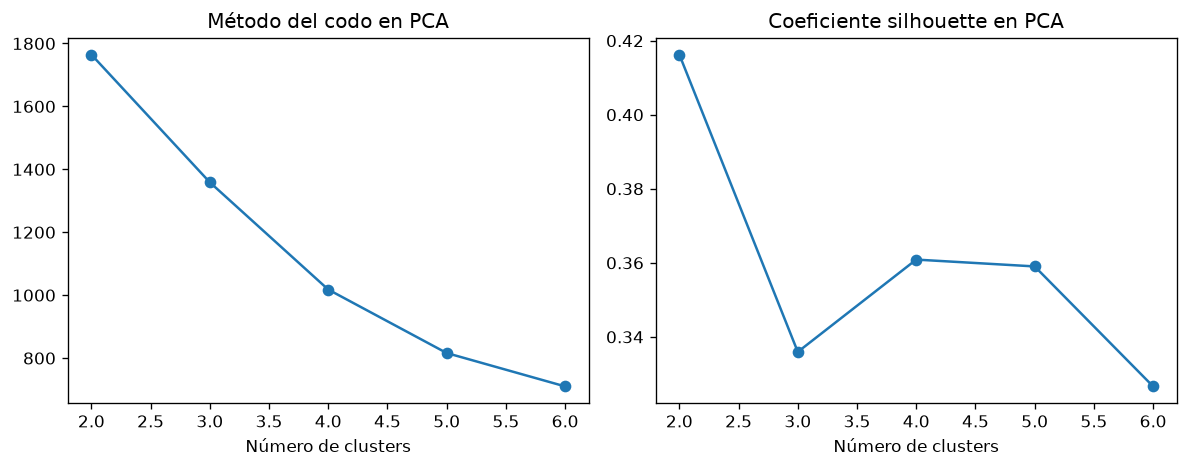

In [3]:
# Limito el aviso de detección de núcleos de joblib en Colab.
import os  # Configuro el entorno de ejecución.
os.environ['LOKY_MAX_CPU_COUNT'] = '2'  # Indico un número seguro de núcleos para joblib.

# Importo las herramientas para preparar los datos, reducir dimensiones y agrupar.
import matplotlib.pyplot as plt  # Dibujo las métricas.
from sklearn.impute import SimpleImputer  # Completo posibles valores ausentes.
from sklearn.preprocessing import StandardScaler  # Pongo las variables en escalas comparables.
from sklearn.decomposition import PCA  # Reduzco las variables a dos componentes principales.
from sklearn.cluster import KMeans  # Agrupo los compuestos.
from sklearn.metrics import silhouette_score  # Evalúo cohesión y separación de los grupos.

# Selecciono cinco propiedades fisicoquímicas para describir los grupos.
variables_cluster = ['MolWt', 'TPSA', 'NumHDonors', 'NumHAcceptors', 'NumRotatableBonds']  # Defino las variables del clustering.
variables_cluster = [variable for variable in variables_cluster if variable in train_df.columns]  # Confirmo que estén disponibles.

# Ajusto la imputación y la estandarización únicamente con entrenamiento.
imputador = SimpleImputer(strategy='median')  # Creo la imputación por mediana.
imputador.fit(train_df[variables_cluster])  # Aprendo las medianas de train.
X_imputado = imputador.transform(train_df[variables_cluster])  # Transformo train con las medianas aprendidas.
escalador = StandardScaler()  # Creo el escalador.
X_estandar = escalador.fit_transform(X_imputado)  # Aprendo y aplico escala en train.

# Ajusto PCA con las variables estandarizadas y obtengo las dos primeras dimensiones.
pca = PCA(n_components=2)  # Defino una PCA bidimensional.
X_pca = pca.fit_transform(X_estandar)  # Proyecta los compuestos a PC1 y PC2.
varianza_pca = pd.Series(pca.explained_variance_ratio_, index=['PC1', 'PC2'])  # Calculo la varianza explicada.
print('Varianza explicada por componente:')  # Presento la proporción explicada.
display((100 * varianza_pca).round(1).to_frame('porcentaje'))  # Muestro la varianza en porcentaje.
print(f'Las dos componentes explican {100 * pca.explained_variance_ratio_.sum():.1f}% de la variación de estas cinco propiedades.')  # Resumo la información conservada.

# Comparo de dos a seis grupos usando las dos componentes principales.
resultados = []  # Creo una lista para guardar las métricas.
for k in range(2, 7):  # Pruebo varios valores de k.
    ajuste = KMeans(n_clusters=k, random_state=42, n_init=20)  # Defino un modelo reproducible.
    etiquetas = ajuste.fit_predict(X_pca)  # Ajusto K-means en PC1 y PC2.
    resultados.append({'k': k, 'WCSS': ajuste.inertia_, 'silhouette': silhouette_score(X_pca, etiquetas)})  # Guardo métricas de PCA.
tabla_k = pd.DataFrame(resultados)  # Creo una tabla de resultados.
display(tabla_k.round(3))  # Muestro WCSS y silhouette.

# Dibujo el codo y silhouette en figuras separadas.
fig, axes = plt.subplots(1, 2, figsize=(10, 4))  # Creo dos paneles.
axes[0].plot(tabla_k['k'], tabla_k['WCSS'], marker='o')  # Dibujo el WCSS.
axes[0].set_title('Método del codo en PCA')  # Titulo el primer panel.
axes[0].set_xlabel('Número de clusters')  # Etiqueto el eje horizontal.
axes[1].plot(tabla_k['k'], tabla_k['silhouette'], marker='o')  # Dibujo silhouette.
axes[1].set_title('Coeficiente silhouette en PCA')  # Titulo el segundo panel.
axes[1].set_xlabel('Número de clusters')  # Etiqueto el eje horizontal.
plt.tight_layout()  # Ajusto los paneles.
plt.show()  # Muestro los gráficos.


## 6.3. Visualización de los grupos en PCA

Elijo el valor de k con mayor silhouette y ajusto K-means en PC1 y PC2. Muestro la misma proyección coloreada primero por cluster y después por etiqueta DILI; la etiqueta no se usa para formar los grupos.


Número de clusters elegido: 2
Elijo k = 2 porque obtiene la silueta más alta entre los valores probados (0.416); reviso también el codo antes de interpretarlo.


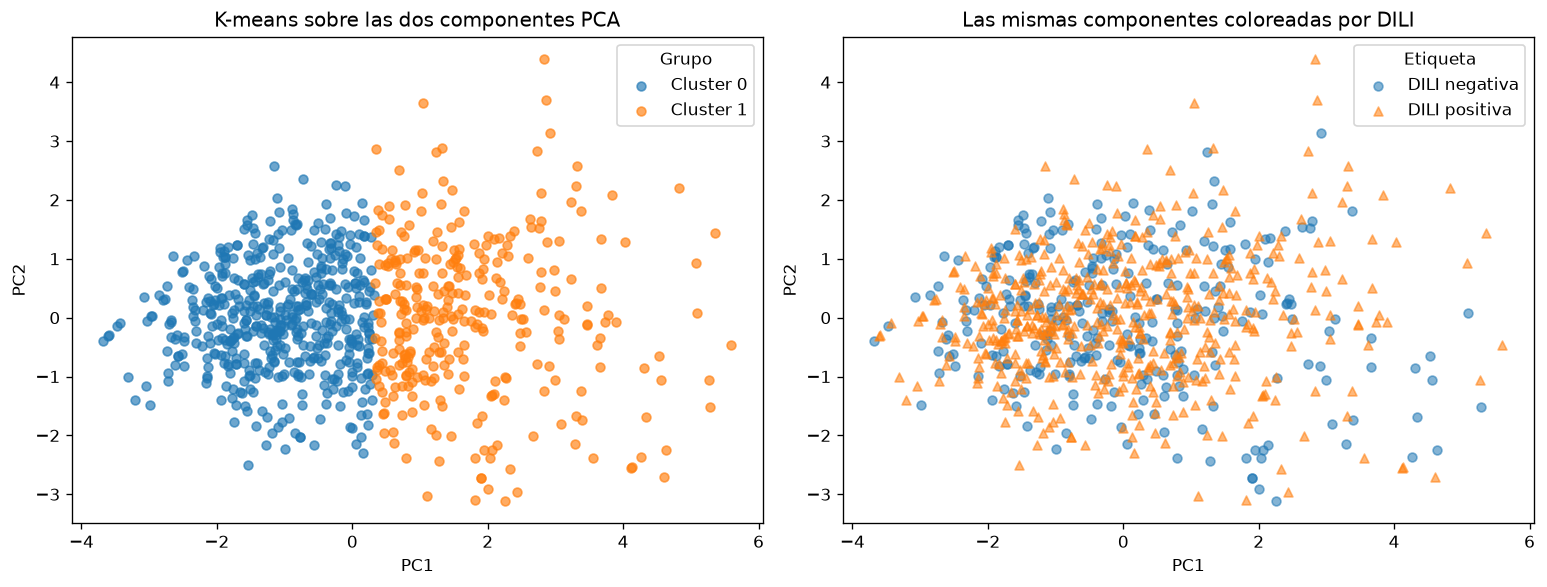

In [4]:
# Selecciono k según la silueta y ajusto el modelo final sobre PC1 y PC2.
k_final = int(tabla_k.loc[tabla_k['silhouette'].idxmax(), 'k'])  # Elijo k con mayor silhouette.
modelo_cluster = KMeans(n_clusters=k_final, random_state=42, n_init=20)  # Creo K-means final.
clusters_train = modelo_cluster.fit_predict(X_pca)  # Ajusto K-means con las dos componentes.
print('Número de clusters elegido:', k_final)  # Informo el número de grupos.
mejor_silueta = tabla_k.loc[tabla_k['k'] == k_final, 'silhouette'].iloc[0]  # Recupero el silhouette del k elegido.
print(f"Elijo k = {k_final} porque obtiene la silueta más alta entre los valores probados ({mejor_silueta:.3f}); reviso también el codo antes de interpretarlo.")  # Justifico la selección con el resultado.

# Añado cluster y componentes principales a los datos de entrenamiento.
train_cluster = train_df.copy()  # Copio los registros de entrenamiento.
train_cluster['cluster'] = clusters_train  # Añado la asignación de grupo.
train_cluster['PC1'] = X_pca[:, 0]  # Añado la primera componente.
train_cluster['PC2'] = X_pca[:, 1]  # Añado la segunda componente.

# Comparo la distribución espacial por cluster y por clase DILI.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))  # Creo dos paneles para la proyección.
for cluster in sorted(train_cluster['cluster'].unique()):  # Recorro los clusters encontrados.
    parte = train_cluster[train_cluster['cluster'] == cluster]  # Selecciono un grupo.
    axes[0].scatter(parte['PC1'], parte['PC2'], alpha=0.65, s=28, label=f'Cluster {cluster}')  # Muestro sus compuestos.
axes[0].set_title('K-means sobre las dos componentes PCA')  # Titulo el primer panel.
axes[0].set_xlabel('PC1')  # Etiqueto la primera componente.
axes[0].set_ylabel('PC2')  # Etiqueto la segunda componente.
axes[0].legend(title='Grupo')  # Añado la leyenda de clusters.
for clase, nombre, marcador in [(0, 'DILI negativa', 'o'), (1, 'DILI positiva', '^')]:  # Recorro las etiquetas solo para mostrar.
    parte = train_cluster[train_cluster['DILI'] == clase]  # Selecciono una clase observada.
    axes[1].scatter(parte['PC1'], parte['PC2'], alpha=0.55, s=28, marker=marcador, label=nombre)  # Dibujo la clase.
axes[1].set_title('Las mismas componentes coloreadas por DILI')  # Titulo el segundo panel.
axes[1].set_xlabel('PC1')  # Etiqueto la primera componente.
axes[1].set_ylabel('PC2')  # Etiqueto la segunda componente.
axes[1].legend(title='Etiqueta')  # Añado la leyenda de DILI.
plt.tight_layout()  # Ajusto los dos gráficos.
plt.show()  # Muestro las proyecciones.


## 6.4. Perfiles químicos y ejemplos de estructuras

Comparo el tamaño de los grupos, sus medias en las cinco variables originales y la proporción de etiquetas DILI positivas. Después selecciono hasta tres compuestos positivos cercanos al centro del grupo con mayor proporción positiva y dibujo sus estructuras como ejemplos representativos.


El cluster 1 tiene la mayor proporción de etiquetas DILI positivas (64.6%).
La proporción global de train es 63.8%; la diferencia del grupo es +0.7 puntos porcentuales.
Esta proporción describe la composición de DILIst en este análisis, no el riesgo clínico de los fármacos.
El cluster más pequeño es el 1: 316 compuestos (38.3% de train).


,n,positivos,porcentaje_DILI_positiva,diferencia_pp_vs_train
cluster,,,,
1,316,204,64.6,0.7
0,508,322,63.4,-0.4


,MolWt,TPSA,NumHDonors,NumHAcceptors,NumRotatableBonds
cluster,,,,,
0,277.65,49.17,1.09,2.93,3.23
1,398.06,111.01,2.59,5.93,6.31


,centro_PC1,centro_PC2
0,-1.07,-0.0
1,1.72,0.0


,CompoundName,InChIKey,DILI,distancia_al_centro
396,Gabexate,YKGYIDJEEQRWQH-UHFFFAOYSA-N,1,0.091
430,cefalotin,XIURVHNZVLADCM-IUODEOHRSA-N,1,0.157
752,etravirine,PYGWGZALEOIKDF-UHFFFAOYSA-N,1,0.161


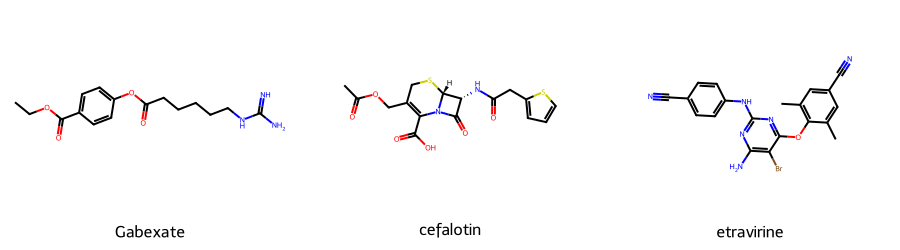

In [5]:
# Calculo el tamaño y la proporción de DILI positiva de cada cluster.
perfil_dili = train_cluster.groupby('cluster').agg(n=('DILI', 'size'), positivos=('DILI', 'sum'), proporcion_DILI_positiva=('DILI', 'mean'))  # Resumo el tamaño y la clase.
perfil_dili['porcentaje_DILI_positiva'] = (100 * perfil_dili['proporcion_DILI_positiva']).round(1)  # Expreso la proporción en porcentaje.
prevalencia_train = train_cluster['DILI'].mean()  # Calculo el porcentaje global de positivos en train.
perfil_dili['diferencia_pp_vs_train'] = (100 * (perfil_dili['proporcion_DILI_positiva'] - prevalencia_train)).round(1)  # Comparo cada grupo con el total en puntos porcentuales.
display(perfil_dili.drop(columns='proporcion_DILI_positiva').sort_values('porcentaje_DILI_positiva', ascending=False))  # Ordeno los grupos por proporción positiva.

# Describo cada grupo en las unidades originales de las cinco propiedades.
perfiles_quimicos = train_cluster.groupby('cluster')[variables_cluster].mean().round(2)  # Calculo las medias químicas.
display(perfiles_quimicos)  # Muestro los perfiles fisicoquímicos.
centros_pca = pd.DataFrame(modelo_cluster.cluster_centers_, columns=['centro_PC1', 'centro_PC2'])  # Organizo los centros en el plano PCA.
display(centros_pca.round(2))  # Muestro la ubicación de los centros.

# Selecciono el grupo con mayor proporción de etiquetas DILI positivas.
cluster_mas_positivo = int(perfil_dili['proporcion_DILI_positiva'].idxmax())  # Identifico el grupo con mayor proporción positiva.
print(f'El cluster {cluster_mas_positivo} tiene la mayor proporción de etiquetas DILI positivas ({perfil_dili.loc[cluster_mas_positivo, "porcentaje_DILI_positiva"]:.1f}%).')  # Informo el resultado descriptivo.
print(f'La proporción global de train es {100 * prevalencia_train:.1f}%; la diferencia del grupo es {perfil_dili.loc[cluster_mas_positivo, "diferencia_pp_vs_train"]:+.1f} puntos porcentuales.')  # Comparo con la frecuencia general.
print('Esta proporción describe la composición de DILIst en este análisis, no el riesgo clínico de los fármacos.')  # Aclaro el alcance de la interpretación.
cluster_menor = int(perfil_dili['n'].idxmin())  # Localizo el grupo de menor tamaño.
porcentaje_menor = 100 * perfil_dili.loc[cluster_menor, 'n'] / len(train_cluster)  # Calculo qué parte de train representa.
print(f"El cluster más pequeño es el {cluster_menor}: {int(perfil_dili.loc[cluster_menor, 'n'])} compuestos ({porcentaje_menor:.1f}% de train).")  # Pongo el tamaño en contexto.
if porcentaje_menor < 5:  # Compruebo si el grupo pequeño es minoritario.
    print('Lo interpreto con cautela: un grupo tan pequeño puede separar moléculas extremas y su porcentaje DILI es inestable.')  # Evito generalizar su composición.

# Busco ejemplos DILI positivos próximos al centro de ese grupo en el plano PCA.
positivos_grupo = train_cluster[(train_cluster['cluster'] == cluster_mas_positivo) & (train_cluster['DILI'] == 1)].copy()  # Selecciono positivos del cluster.
centro = modelo_cluster.cluster_centers_[cluster_mas_positivo]  # Tomo el centro del cluster en PCA.
positivos_grupo['distancia_al_centro'] = np.sqrt((positivos_grupo['PC1'] - centro[0]) ** 2 + (positivos_grupo['PC2'] - centro[1]) ** 2)  # Calculo distancia a ese centro.
ejemplos = positivos_grupo.sort_values('distancia_al_centro').head(3)  # Tomo hasta tres ejemplos representativos.
display(ejemplos[['CompoundName', 'InChIKey', 'DILI', 'distancia_al_centro']].round(3))  # Muestro sus identificadores.

# Dibujo las estructuras moleculares de esos ejemplos con RDKit.
from rdkit import Chem  # Convierto SMILES a moléculas.
from rdkit.Chem import Draw  # Dibujo las estructuras.
moleculas = []  # Creo una lista de moléculas válidas.
leyendas = []  # Creo una lista de nombres para las figuras.
for _, fila in ejemplos.iterrows():  # Recorro los ejemplos seleccionados.
    molecula = Chem.MolFromSmiles(fila['SMILES'])  # Construyo la molécula desde SMILES.
    if molecula is not None:  # Compruebo que la estructura se haya leído bien.
        moleculas.append(molecula)  # Guardo la molécula válida.
        leyendas.append(str(fila['CompoundName']))  # Guardo el nombre asociado.
if moleculas:  # Compruebo que haya estructuras para mostrar.
    display(Draw.MolsToGridImage(moleculas, molsPerRow=3, subImgSize=(300, 250), legends=leyendas))  # Muestro las estructuras juntas.


## Interpretación

Interpreto los clusters por su tamaño, sus medias fisicoquímicas y su porcentaje de DILI positiva. Comparo esa proporción con la frecuencia global de positivos en entrenamiento para evitar leer el porcentaje del grupo de forma aislada. Las dos componentes PCA facilitan la visualización, pero resumen solo la variación que se indica en el resultado. Si aparece un grupo pequeño de compuestos extremos, sus porcentajes son inestables y conviene leer sus perfiles con cautela. Los ejemplos dibujados son compuestos etiquetados como DILI positivos dentro del grupo seleccionado; no implican que una estructura concreta cause la lesión ni que el porcentaje del grupo sea un riesgo clínico.
